# Random processes 2: Random walks, Brownian motion and arrivals

*Learning path: random processes, part 2 of 3.* [Index](README.md) · Previous: [Markov chains](01-markov-chains.ipynb) · Next: [Stochastic differential equations, options and magnets](03-sdes-options-and-magnets.ipynb)

In 1827 the botanist Robert Brown watched pollen grains under a microscope and saw tiny particles inside them jitter
without end. In 1905 Albert Einstein explained the jitter as the sum of countless kicks from water molecules, and
showed how measuring it would reveal the size of atoms; Jean Perrin did the measurement and won the Nobel prize. The
mathematics is the **random walk**: add up many small random steps. This lesson builds random walks, finds the
square-root law of their spread, passes to the limit of Brownian motion, and ends with the other basic random process,
random arrivals in time.

**Who this is for.** Students who have done [lesson 1](01-markov-chains.ipynb) and know the mean, standard deviation and
the normal distribution ([statistics 1 to 5](../statistics/README.md)).

**What you will be able to do afterwards:**

1. simulate random walks in one and two dimensions;
2. explain why the spread after $n$ steps grows like $\sqrt n$, and see the central limit theorem in action;
3. simulate Brownian motion and state its defining properties;
4. simulate a Poisson process and recognise exponential waiting times.

Plan about 45 minutes. Each section ends with a **Try this**; exercises, hints and answers are at the end.

## 1. The simple random walk

Start at 0 and take steps of $+1$ or $-1$ with equal chance. `randwalk(n)` gives the positions after $0, 1, \dots, n$
steps:

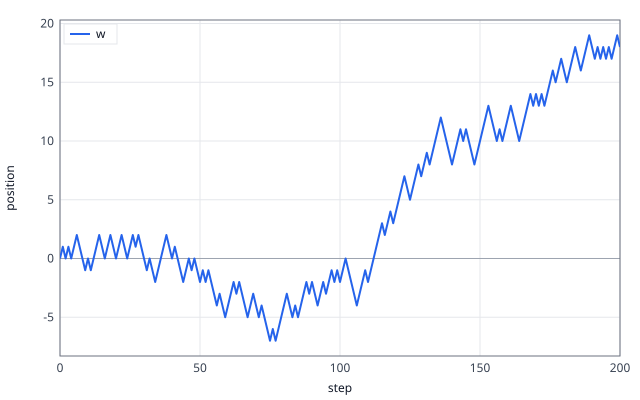

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [1]:
seed(1);
w = randwalk(200);
labels(plot(0:200, w), "step", "position")

The walk wanders far from 0 and comes back, with long excursions to one side. It is a Markov chain on the integers:
the next position depends only on the current one.

**Try this.** Run it again with other seeds. Does the walk spend about half its time above 0? (It usually does not:
by the arcsine law, a lopsided split is more likely than an even one.)

## 2. The square-root law

Where does the walk end after 100 steps? Each step has mean 0 and variance 1, and the steps are independent, so the
sum $S_{100}$ has mean 0 and variance 100: its standard deviation is $\sqrt{100} = 10$. Let us check with 2000 walks:

-0.306

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

9.83

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

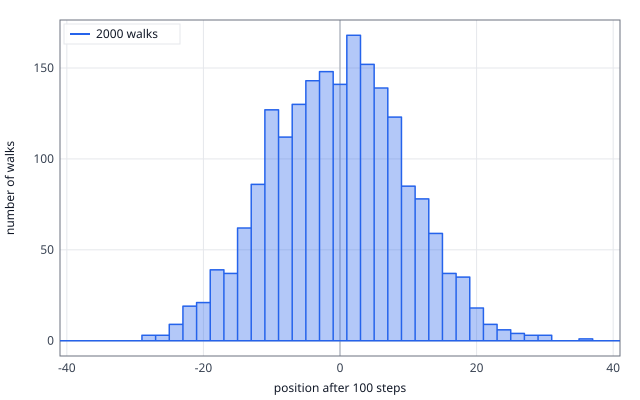

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [2]:
seed(2);
ends = zeros(1, 2000);
for k = 1:2000
  w = randwalk(100);
  ends(k) = w(101);
end
eval(mean(ends), 3)
eval(std(ends), 3)
labels(legend(hist(ends, -41:2:41), "2000 walks"), "position after 100 steps", "number of walks")

The spread is close to 10, and the histogram is bell-shaped: the central limit theorem at work. The typical distance
after $n$ steps grows only like $\sqrt n$. To get twice as far you need four times as many steps. This is why
diffusion is slow over long distances: a molecule of perfume crosses a room by diffusion alone in days, not seconds.

**Try this.** Repeat with 400 steps (use `w(401)`). What standard deviation do you expect?

## 3. Walks in the plane

`randwalk(n, 2)` walks on the square grid, one row $[x, y]$ per position:

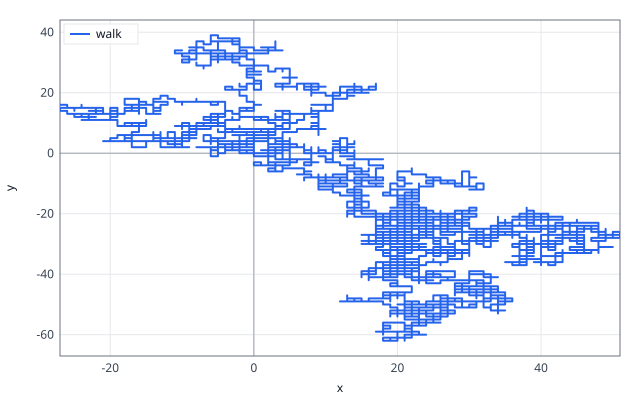

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
seed(5);
Z = randwalk(5000, 2);
labels(legend(plot(column(Z, 1), column(Z, 2)), "walk"), "x", "y")

This is what Brown saw. George Pólya proved in 1921 that a random walk on the line or in the plane returns to its start
with certainty, but in three dimensions it returns only with chance about $0.34$: "a drunk man will find his way home,
but a drunk bird may get lost forever."

**Try this.** For a 2-dimensional walk, the distance from the start after $n$ steps is also about $\sqrt n$. Check
the last row of `Z`: is its distance from the origin of the order of $\sqrt{5000} \approx 71$?

## 4. Brownian motion

Now take a walk with very many very small steps: $n$ steps of size $\sqrt{T/n}$ in time $T$. As $n \to \infty$ the
limit is **Brownian motion** $W(t)$ (also called the Wiener process, after Norbert Wiener, who built it rigorously in
1923). It is defined by three properties:

1. $W(0) = 0$, and its path is continuous;
2. the increment $W(t) - W(s)$ is normal with mean 0 and variance $t - s$;
3. increments over separate time intervals are independent.

`brownian(T, n)` gives one path at the times $0, T/n, \dots, T$, and `brownian(T, n, k)` gives $k$ paths, one per row:

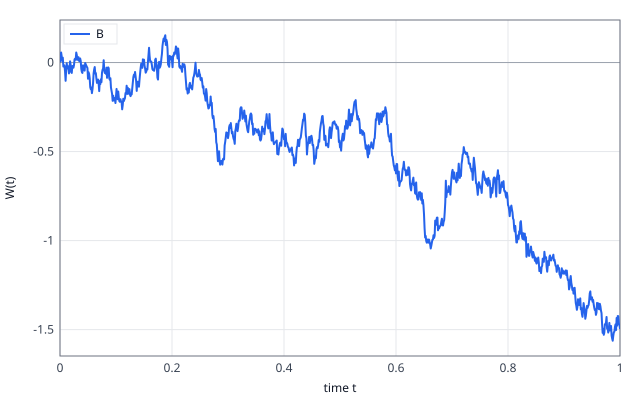

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
seed(3);
B = brownian(1, 1000);
t = linspace(0, 1, 1001);
labels(plot(t, B), "time t", "W(t)")

The path is continuous but so rough that it has no slope anywhere: zoom in and it looks just as jagged. Its variance
at time 1 should be 1. With 4000 paths of 10 steps each:

In [5]:
seed(4);
M = brownian(1, 10, 4000);
eval(var(column(M, 11)), 3)
eval(var(column(M, 6)), 3)

0.981

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.495

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

At time $1/2$ (column 6) the variance is about $1/2$: the variance grows linearly in time, the square-root law again.

**Try this.** For Brownian motion, the chance that $W(1) > 1$ is $1 - \Phi(1) \approx 0.16$. Estimate it from column
11 of `M` by counting.

## 5. Random arrivals: the Poisson process

Customers arrive at a shop, radioactive atoms decay, emails come in: events at random times, at a steady average
rate $\lambda$, independent of each other. This is the **Poisson process**. `arrivals(rate, T)` lists the arrival times
up to time $T$:

In [6]:
seed(6);
a = arrivals(3, 10)
length(a)

[0.2084474730412592, 0.29934320106505957, 0.6434641132442553, 0.6793397134929843, 1.179306562408458, 2.219324785452267, 2.4510042218645625, 3.317530740798464, 3.326632448447121, 4.07162052693875, 4.246057663811735, 4.291597372707769, 4.319842963040722, 4.425638405458592, 4.608625036041679, 5.021174396013866, 5.0776870479094045, 5.43018367707526, 5.693610524763169, 6.329188608959692, 6.479381115977983, 7.0769253364837565, 7.574348285519487, 7.830440478832334, 8.239067112786135, 8.475455253187443, 8.97739425548421, 9.524867736926058, 9.733319496193305]

> 29 arrivals (on average rate * T = 30.0); the gaps between them are exponential with mean 1/rate

29

On average $\lambda T = 30$ arrivals, and the count is Poisson distributed ([statistics 3](../statistics/03-discrete-distributions.ipynb)).
The gaps between arrivals are **exponential** with mean $1/\lambda$, and memoryless: having waited a while does not make
the next arrival come sooner. Let us look at the gaps of a long run:

0.328

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.336

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

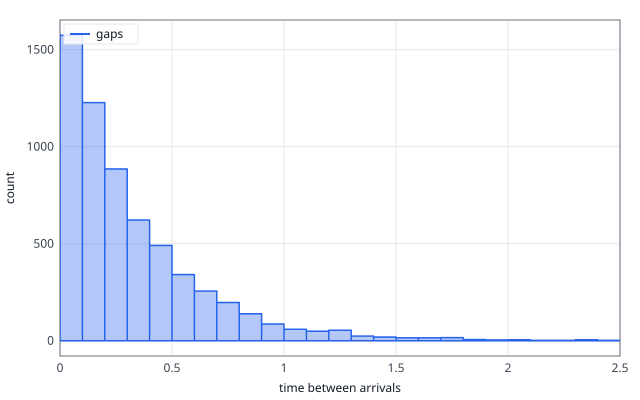

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
seed(7);
a = arrivals(3, 2000);
n = length(a);
gaps = zeros(1, n - 1);
for k = 1:n - 1
  gaps(k) = a(k + 1) - a(k);
end
eval(mean(gaps), 3)
eval(std(gaps), 3)
labels(legend(hist(gaps, 0:0.1:2.5), "gaps"), "time between arrivals", "count")

The mean and the standard deviation are both close to $1/3$, as for an exponential distribution, and the histogram
falls off exponentially.

**Try this.** The waiting-time paradox: buses arrive as a Poisson process with a mean gap of 10 minutes. If you arrive
at a random moment, the mean wait until the next bus is 10 minutes, not 5. Can you explain why? (Hint: you are more
likely to arrive during a long gap.)

## Summary

* A random walk adds independent steps; after $n$ steps its spread is $\sqrt n$ and its end point is roughly normal.
* In one and two dimensions a random walk always returns home; in three it may not.
* Brownian motion is the limit of random walks with tiny steps: continuous, with independent normal increments of
  variance equal to the elapsed time.
* A Poisson process of rate $\lambda$ has Poisson counts and exponential gaps of mean $1/\lambda$.

Next: [stochastic differential equations, options and magnets](03-sdes-options-and-magnets.ipynb).

## Exercises

1. **Return to zero.** For a 1-dimensional walk of 1000 steps, count how many times it is at 0. Repeat for 4000
   steps. How does the count grow?
2. **Three dimensions.** Walk 5000 steps with `randwalk(5000, 3)`. Plot $x$ against $y$; compare with section 3.
3. **Scaling.** If $W$ is Brownian motion, then $W(4t)/2$ is too. Check with the variances of a simulated
   `brownian(4, 400, 2000)` at times 1 and 4.
4. **Two shops.** Two independent Poisson processes with rates 2 and 3 together form a Poisson process of rate 5.
   Simulate both up to time 100 and count.
5. **Maximum.** Estimate the chance that a Brownian path on $[0, 1]$ ever goes above 1. Compare with
   $2(1 - \Phi(1)) \approx 0.32$ (the reflection principle).

## Hints and answers

* **Section 1, Try this.** Seldom: shares near 0 or 1 are the most likely, by the arcsine law.
* **Section 2, Try this.** $\sqrt{400} = 20$.
* **Section 3, Try this.** Yes; the distance is random, of the order of 70.
* **Section 4, Try this.** About 0.16.
* **Section 5, Try this.** Long gaps cover more of the clock, so a random moment more likely falls in one; by
  memorylessness, the remaining wait is still exponential with mean 10.
* **Exercise 1.** It grows like $\sqrt n$: about twice as many visits for four times as many steps.
* **Exercise 2.** The 3-dimensional walk spreads similarly, but visits its start less often.
* **Exercise 3.** Both variances scale with time: about 1 and 4.
* **Exercise 4.** About $500 = 200 + 300$ arrivals in all.
* **Exercise 5.** Use a fine grid (for example `brownian(1, 1000, 2000)`) and `max` of each row; the estimate is a
  little below 0.32 because a grid misses peaks between its points.

## Sources

1. A. Einstein, "Über die von der molekularkinetischen Theorie der Wärme geforderte Bewegung von in ruhenden
   Flüssigkeiten suspendierten Teilchen", *Annalen der Physik* 17 (1905) 549–560.
2. G. Pólya, "Über eine Aufgabe der Wahrscheinlichkeitsrechnung betreffend die Irrfahrt im Straßennetz",
   *Mathematische Annalen* 84 (1921) 149–160.
3. N. Wiener, "Differential-space", *Journal of Mathematics and Physics* 2 (1923) 131–174.
4. W. Feller, *An Introduction to Probability Theory and Its Applications*, vol. 1, 3rd ed., Wiley (1968), chapter III
   (fluctuations in coin tossing and the arcsine law).
5. G. R. Grimmett and D. R. Stirzaker, *Probability and Random Processes*, 3rd ed., Oxford University Press (2001),
   chapters 6 and 13.